In [3]:
import pandas as pd 

In [4]:
import sys
from pathlib import Path

# ============================================================
# 0. PROJECT PATH
# ============================================================

sys.path.insert(0, r"C:\liverCTSegmentation")


# ============================================================
# 1. IMPORTS
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt

from src.config import IMAGE_DIR, MASK_DIR
from src.preprocessing import load_image_mask


# ============================================================
# 2. CHECK DATASET FOLDERS
# ============================================================

print("=" * 60)
print("DATASET FOLDER CHECK")
print("=" * 60)

print("Image folder:", IMAGE_DIR)
print("Image folder exists:", IMAGE_DIR.exists())

print("Mask folder :", MASK_DIR)
print("Mask folder exists :", MASK_DIR.exists())


if not IMAGE_DIR.exists():
    raise ValueError("IMAGE_DIR does not exist. Check config.py")

if not MASK_DIR.exists():
    raise ValueError("MASK_DIR does not exist. Check config.py")




DATASET FOLDER CHECK
Image folder: C:\Users\vivek chauhan\Desktop\dsa babbar\Videos\archive (26)\last_dataset\images
Image folder exists: True
Mask folder : C:\Users\vivek chauhan\Desktop\dsa babbar\Videos\archive (26)\last_dataset\masks
Mask folder exists : True


In [5]:
# ============================================================
# 3. GET IMAGE AND MASK FILES
# ============================================================

image_paths = sorted(IMAGE_DIR.glob("*.png"))
mask_paths = sorted(MASK_DIR.glob("*.png"))

print("\n" + "=" * 60)
print("DATASET SIZE")
print("=" * 60)

print("Number of images:", len(image_paths))
print("Number of masks :", len(mask_paths))


if len(image_paths) == 0:
    raise ValueError("No PNG images found. Check IMAGE_DIR.")

if len(mask_paths) == 0:
    raise ValueError("No PNG masks found. Check MASK_DIR.")


# ============================================================
# 4. IMAGE-MASK PAIRING CHECK
# ============================================================

image_names = {p.name for p in image_paths}
mask_names = {p.name for p in mask_paths}

common_names = image_names.intersection(mask_names)

images_without_masks = image_names - mask_names
masks_without_images = mask_names - image_names

print("\n" + "=" * 60)
print("IMAGE-MASK PAIRING")
print("=" * 60)

print("Matching pairs:", len(common_names))
print("Images without masks:", len(images_without_masks))
print("Masks without images:", len(masks_without_images))





DATASET SIZE
Number of images: 58638
Number of masks : 58638

IMAGE-MASK PAIRING
Matching pairs: 58638
Images without masks: 0
Masks without images: 0


In [6]:
# ============================================================
# 5. SAMPLE PREPROCESSING CHECK
# ============================================================

image, mask = load_image_mask(
    image_paths[0],
    mask_paths[0]
)

print("\n" + "=" * 60)
print("SAMPLE PREPROCESSING CHECK")
print("=" * 60)

print("First image:")
print("Path:", image_paths[0])

print("\nFirst mask:")
print("Path:", mask_paths[0])

print("\nProcessed image shape:", image.shape)
print("Processed mask shape :", mask.shape)

print("\nImage min:", image.min())
print("Image max:", image.max())

print("\nMask unique values:", np.unique(mask))




SAMPLE PREPROCESSING CHECK
First image:
Path: C:\Users\vivek chauhan\Desktop\dsa babbar\Videos\archive (26)\last_dataset\images\Volume-000-000.png

First mask:
Path: C:\Users\vivek chauhan\Desktop\dsa babbar\Videos\archive (26)\last_dataset\masks\Volume-000-000.png

Processed image shape: (128, 128, 1)
Processed mask shape : (128, 128, 1)

Image min: 0.0
Image max: 1.0

Mask unique values: [0.]


In [7]:

# ============================================================
# 6. FULL DATASET MASK ANALYSIS
# ============================================================

print("\n" + "=" * 60)
print("FULL DATASET MASK ANALYSIS")
print("=" * 60)

empty_masks = 0
non_empty_masks = 0

liver_areas = []

for i, mask_path in enumerate(mask_paths):

    mask_img = cv2.imread(
        str(mask_path),
        cv2.IMREAD_GRAYSCALE
    )

    if mask_img is None:
        continue

    # Resize mask
    mask_img = cv2.resize(
        mask_img,
        (128, 128),
        interpolation=cv2.INTER_NEAREST
    )

    # Convert to binary
    binary_mask = mask_img > 127

    # Count foreground/liver pixels
    foreground_pixels = np.sum(binary_mask)

    if foreground_pixels == 0:

        empty_masks += 1

    else:

        non_empty_masks += 1
        liver_areas.append(foreground_pixels)

    # Progress
    if (i + 1) % 5000 == 0:
        print(
            f"Processed {i + 1} / {len(mask_paths)} masks"
        )


print("\nTotal masks:", len(mask_paths))
print("Empty masks:", empty_masks)
print("Non-empty masks:", non_empty_masks)

empty_percentage = (
    empty_masks / len(mask_paths)
) * 100

non_empty_percentage = (
    non_empty_masks / len(mask_paths)
) * 100

print(
    f"Empty mask percentage: {empty_percentage:.2f}%"
)

print(
    f"Non-empty mask percentage: {non_empty_percentage:.2f}%"
)




FULL DATASET MASK ANALYSIS
Processed 5000 / 58638 masks
Processed 10000 / 58638 masks
Processed 15000 / 58638 masks
Processed 20000 / 58638 masks
Processed 25000 / 58638 masks
Processed 30000 / 58638 masks
Processed 35000 / 58638 masks
Processed 40000 / 58638 masks
Processed 45000 / 58638 masks
Processed 50000 / 58638 masks
Processed 55000 / 58638 masks

Total masks: 58638
Empty masks: 39617
Non-empty masks: 19021
Empty mask percentage: 67.56%
Non-empty mask percentage: 32.44%


In [8]:

# ============================================================
# 7. LIVER AREA STATISTICS
# ============================================================

if len(liver_areas) > 0:

    liver_areas = np.array(liver_areas)

    print("\n" + "=" * 60)
    print("LIVER AREA STATISTICS")
    print("=" * 60)

    print("Minimum liver pixels:",
          liver_areas.min())

    print("Maximum liver pixels:",
          liver_areas.max())

    print("Mean liver pixels:",
          liver_areas.mean())

    print("Median liver pixels:",
          np.median(liver_areas))

    print(
        "Standard deviation:",
        liver_areas.std()
    )



LIVER AREA STATISTICS
Minimum liver pixels: 1
Maximum liver pixels: 3279
Mean liver pixels: 648.7636296724672
Median liver pixels: 337.0
Standard deviation: 739.0866972580227


In [9]:


# ============================================================
# 8. CT IMAGE INTENSITY STATISTICS
# ============================================================

print("\n" + "=" * 60)
print("CT IMAGE INTENSITY STATISTICS")
print("=" * 60)

# Analyze a representative sample instead of
# loading all 58,638 images into memory.

sample_count = min(1000, len(image_paths))

image_mins = []
image_maxs = []
image_means = []
image_stds = []

all_intensities = []

for i, image_path in enumerate(image_paths[:sample_count]):

    img = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE
    )

    if img is None:
        continue

    # Normalize to [0, 1]
    img = img.astype(np.float32) / 255.0

    image_mins.append(img.min())
    image_maxs.append(img.max())
    image_means.append(img.mean())
    image_stds.append(img.std())

    # Sample pixels for histogram
    pixels = img.flatten()

    # Take at most 5000 pixels from each image
    if len(pixels) > 5000:
        pixels = pixels[
            np.linspace(
                0,
                len(pixels) - 1,
                5000
            ).astype(int)
        ]

    all_intensities.extend(pixels.tolist())

    if (i + 1) % 100 == 0:
        print(
            f"Analyzed {i + 1} / {sample_count} images"
        )


if len(image_means) > 0:

    print("\nImages analyzed:", len(image_means))

    print(
        "Average minimum intensity:",
        np.mean(image_mins)
    )

    print(
        "Average maximum intensity:",
        np.mean(image_maxs)
    )

    print(
        "Mean image intensity:",
        np.mean(image_means)
    )

    print(
        "Mean image standard deviation:",
        np.mean(image_stds)
    )

    print(
        "Overall sampled pixel mean:",
        np.mean(all_intensities)
    )

    print(
        "Overall sampled pixel standard deviation:",
        np.std(all_intensities)
    )





CT IMAGE INTENSITY STATISTICS
Analyzed 100 / 1000 images
Analyzed 200 / 1000 images
Analyzed 300 / 1000 images
Analyzed 400 / 1000 images
Analyzed 500 / 1000 images
Analyzed 600 / 1000 images
Analyzed 700 / 1000 images
Analyzed 800 / 1000 images
Analyzed 900 / 1000 images
Analyzed 1000 / 1000 images

Images analyzed: 1000
Average minimum intensity: 0.0
Average maximum intensity: 1.0
Mean image intensity: 0.19643469
Mean image standard deviation: 0.33453655
Overall sampled pixel mean: 0.19621577383656055
Overall sampled pixel standard deviation: 0.33779368575171137


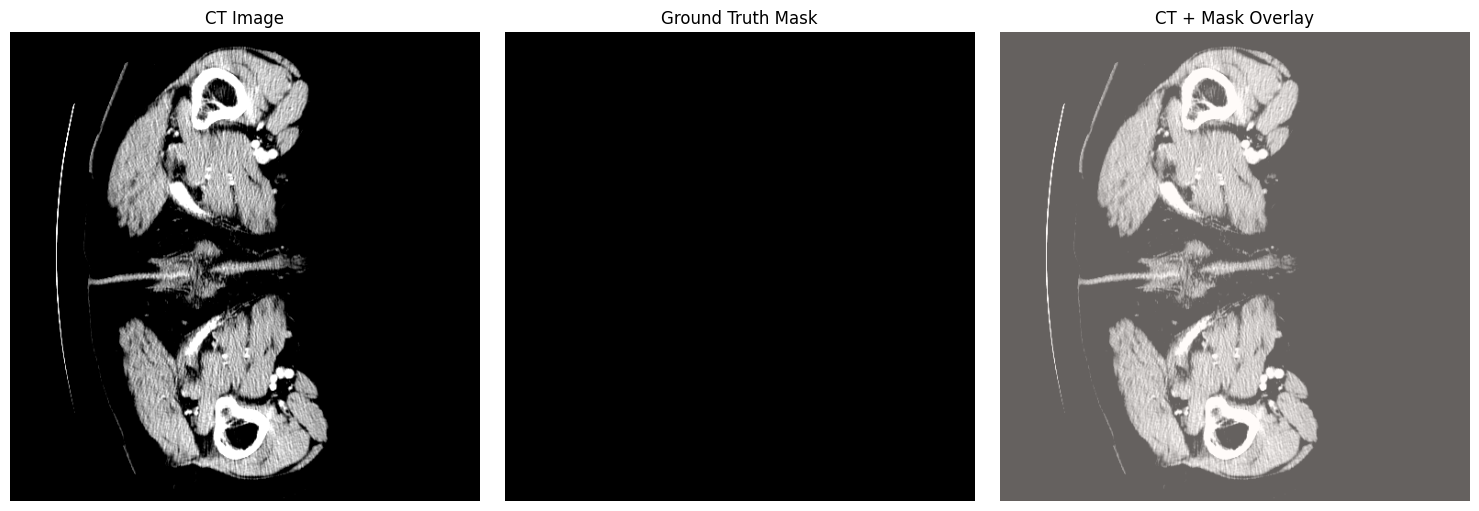

In [10]:
# ============================================================
# 9. VISUALIZE SAMPLE IMAGE AND MASK
# ============================================================

sample_image_path = image_paths[0]
sample_mask_path = mask_paths[0]

raw_image = cv2.imread(
    str(sample_image_path),
    cv2.IMREAD_GRAYSCALE
)

raw_mask = cv2.imread(
    str(sample_mask_path),
    cv2.IMREAD_GRAYSCALE
)


# Resize mask to image size for overlay
raw_mask = cv2.resize(
    raw_mask,
    (raw_image.shape[1], raw_image.shape[0]),
    interpolation=cv2.INTER_NEAREST
)


plt.figure(figsize=(15, 5))


# -----------------------------
# CT Image
# -----------------------------

plt.subplot(1, 3, 1)

plt.imshow(
    raw_image,
    cmap="gray"
)

plt.title("CT Image")
plt.axis("off")


# -----------------------------
# Ground Truth Mask
# -----------------------------

plt.subplot(1, 3, 2)

plt.imshow(
    raw_mask,
    cmap="gray"
)

plt.title("Ground Truth Mask")
plt.axis("off")


# -----------------------------
# Overlay
# -----------------------------

plt.subplot(1, 3, 3)

plt.imshow(
    raw_image,
    cmap="gray"
)

plt.imshow(
    raw_mask,
    cmap="Reds",
    alpha=0.4
)

plt.title("CT + Mask Overlay")
plt.axis("off")


plt.tight_layout()

plt.show()



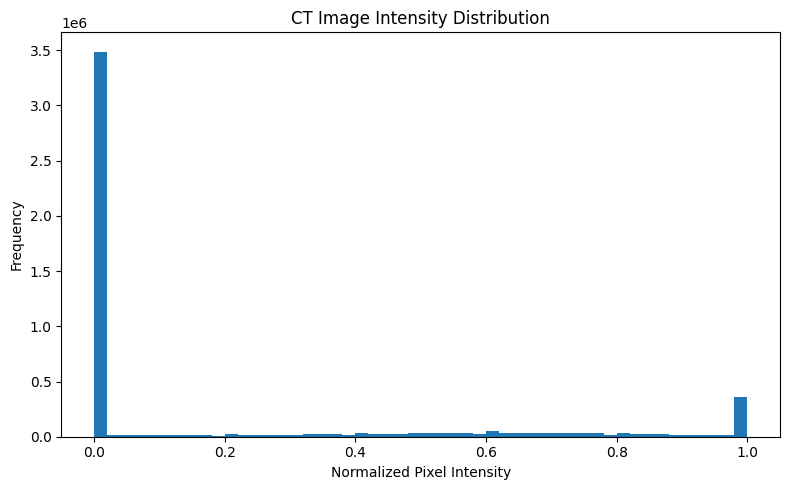

In [11]:

# ============================================================
# 10. CT INTENSITY HISTOGRAM
# ============================================================

if len(all_intensities) > 0:

    plt.figure(figsize=(8, 5))

    plt.hist(
        all_intensities,
        bins=50
    )

    plt.xlabel("Normalized Pixel Intensity")
    plt.ylabel("Frequency")
    plt.title("CT Image Intensity Distribution")

    plt.tight_layout()

    plt.show()


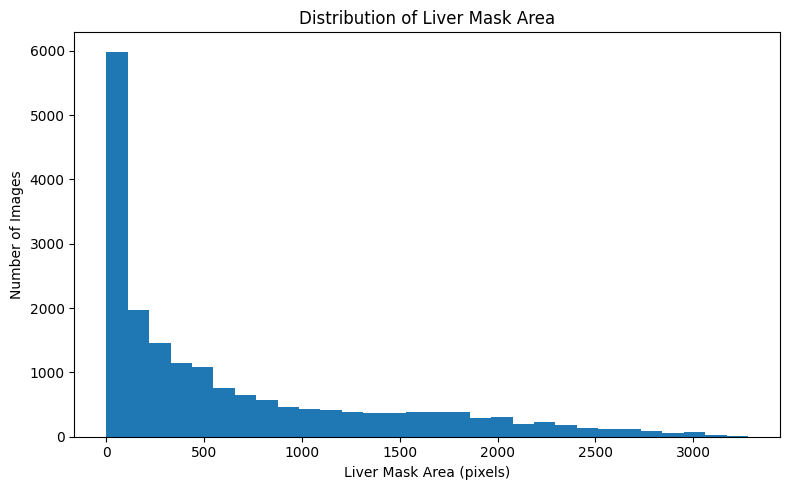

In [12]:


# ============================================================
# 11. LIVER AREA DISTRIBUTION
# ============================================================

if len(liver_areas) > 0:

    plt.figure(figsize=(8, 5))

    plt.hist(
        liver_areas,
        bins=30
    )

    plt.xlabel("Liver Mask Area (pixels)")
    plt.ylabel("Number of Images")
    plt.title("Distribution of Liver Mask Area")

    plt.tight_layout()

    plt.show()



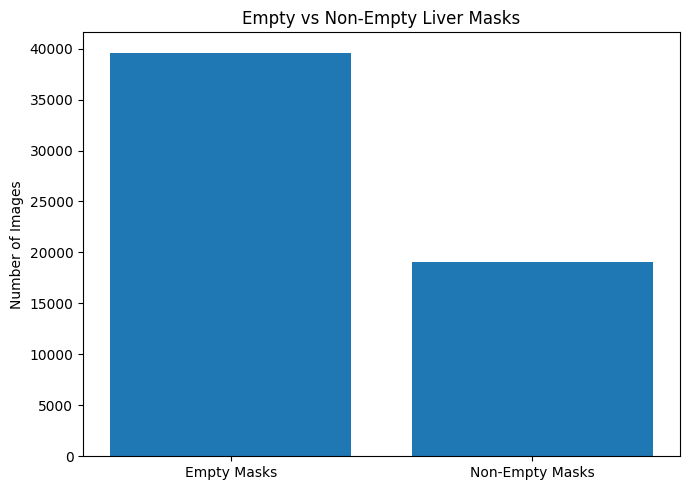

In [13]:

# ============================================================
# 12. EMPTY VS NON-EMPTY MASK DISTRIBUTION
# ============================================================

plt.figure(figsize=(7, 5))

categories = [
    "Empty Masks",
    "Non-Empty Masks"
]

counts = [
    empty_masks,
    non_empty_masks
]

plt.bar(
    categories,
    counts
)

plt.ylabel("Number of Images")
plt.title("Empty vs Non-Empty Liver Masks")

plt.tight_layout()

plt.show()


In [14]:


# ============================================================
# 13. FINAL EDA SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("FINAL EDA SUMMARY")
print("=" * 60)

print("Total images:", len(image_paths))
print("Total masks :", len(mask_paths))
print("Matching pairs:", len(common_names))

print("\nEmpty masks:", empty_masks)
print("Non-empty masks:", non_empty_masks)

print(
    f"Empty masks: {empty_percentage:.2f}%"
)

print(
    f"Non-empty masks: {non_empty_percentage:.2f}%"
)

if len(liver_areas) > 0:

    print(
        "\nMean liver area:",
        round(liver_areas.mean(), 2)
    )

    print(
        "Median liver area:",
        round(float(np.median(liver_areas)), 2)
    )

    print(
        "Maximum liver area:",
        int(liver_areas.max())
    )

print("\nEDA completed successfully.")


FINAL EDA SUMMARY
Total images: 58638
Total masks : 58638
Matching pairs: 58638

Empty masks: 39617
Non-empty masks: 19021
Empty masks: 67.56%
Non-empty masks: 32.44%

Mean liver area: 648.76
Median liver area: 337.0
Maximum liver area: 3279

EDA completed successfully.
